# Failure modes: seeds, local inverse design, missing epistemic uncertainty, readability

The deck lists four limitations that are about behaviour rather than cost (the cost ones are in `scaling.ipynb`):

1. **Non-convex training.** The result depends on the random seed.
2. **Local inverse design.** $\log p(y^* \mid x)$ is multimodal, and gradient ascent finds the mode nearest its start.
3. **Single tree, aleatoric-heavy uncertainty.** The predictive spread comes from leaf noise and routing ambiguity, with no uncertainty about the parameters themselves, so it does not grow away from the data.
4. **Less interpretable.** Oblique, soft splits are weighted sums of several inputs.

Each section below measures one of them and suggests a mitigation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_friedman1
from sklearn.tree import DecisionTreeRegressor

from difftree import DifferentiableTreeRegressor

FIG = Path("../presentation/figures")
summary = {}          # numbers reused in the summary figure

## 1. Seed sensitivity

The 1-D problem from the deck: $f(x) = \sin 1.5x + 0.3x$ with noise that grows for $x > 0$, 400 training points. We fit the same configuration with 8 seeds at depths 4 and 6 and measure the RMSE of the predictive mean against the true $f$. The validation NLL that difftree reports after fitting is available without the truth, so we also check whether choosing the seed with the best validation score picks a good model.

In [2]:
rng = np.random.default_rng(0)
x1 = np.sort(rng.uniform(-3, 3, 400))[:, None]
f1 = lambda x: np.sin(1.5 * x) + 0.3 * x
y1 = f1(x1[:, 0]) + rng.normal(0, 0.05 + 0.25 * (x1[:, 0] > 0) * np.abs(x1[:, 0]) / 3)
xg = np.linspace(-3, 3, 600)[:, None]
xv = rng.uniform(-3, 3, (400, 1))
yv = f1(xv[:, 0]) + rng.normal(0, 0.05 + 0.25 * (xv[:, 0] > 0) * np.abs(xv[:, 0]) / 3)

seeds = range(8)
seed_fits = {}
for D in (4, 6):
    for s in seeds:
        m = DifferentiableTreeRegressor(depth=D, n_epochs=150, random_state=s).fit(x1, y1)
        rmse = np.sqrt(np.mean((m.predict(xg) - f1(xg[:, 0])) ** 2))
        val_score = m.score(xv, yv)          # R^2 on fresh data, no truth needed
        seed_fits[D, s] = (m, rmse, val_score)
    r = [seed_fits[D, s][1] for s in seeds]
    best = max(seeds, key=lambda s: seed_fits[D, s][2])
    print(f"depth {D}: RMSE vs truth min {min(r):.3f}  median {np.median(r):.3f}  max {max(r):.3f}  "
          f"| seed picked by held-out R^2: {best} (RMSE {seed_fits[D, best][1]:.3f})")
sk_rmse = {D: np.sqrt(np.mean((DecisionTreeRegressor(max_depth=D, random_state=0).fit(x1, y1).predict(xg)
                               - f1(xg[:, 0])) ** 2)) for D in (4, 6)}
print("sklearn tree RMSE vs truth:", {D: round(v, 3) for D, v in sk_rmse.items()})

depth 4: RMSE vs truth min 0.108  median 0.261  max 0.335  | seed picked by held-out R^2: 4 (RMSE 0.108)


depth 6: RMSE vs truth min 0.081  median 0.108  max 0.138  | seed picked by held-out R^2: 6 (RMSE 0.081)
sklearn tree RMSE vs truth: {4: np.float64(0.14), 6: np.float64(0.095)}


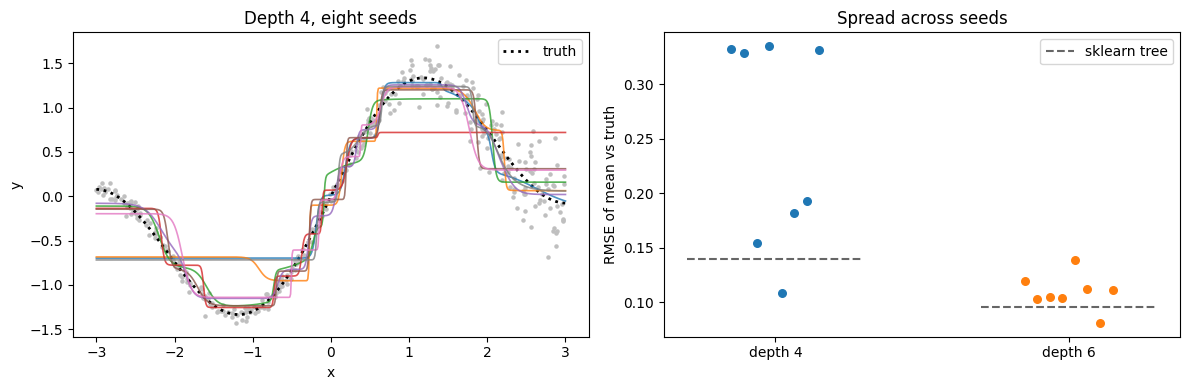

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.scatter(x1[:, 0], y1, s=5, color="0.75")
ax.plot(xg[:, 0], f1(xg[:, 0]), "k:", lw=2, label="truth")
for s in seeds:
    ax.plot(xg[:, 0], seed_fits[4, s][0].predict(xg), lw=1.2, alpha=0.8)
ax.set(xlabel="x", ylabel="y", title="Depth 4, eight seeds")
ax.legend()
ax = axes[1]
for i, D in enumerate((4, 6)):
    r = [seed_fits[D, s][1] for s in seeds]
    ax.scatter(np.full(len(r), i) + np.linspace(-0.15, 0.15, len(r)), r, s=30, color=f"C{i}")
    ax.hlines(sk_rmse[D], i - 0.3, i + 0.3, color="0.4", ls="--", label="sklearn tree" if i == 0 else None)
ax.set_xticks([0, 1], ["depth 4", "depth 6"])
ax.set(ylabel="RMSE of mean vs truth", title="Spread across seeds")
ax.legend()
plt.tight_layout()
plt.show()
summary["seeds"] = {D: [seed_fits[D, s][1] for s in seeds] for D in (4, 6)}

## 2. Inverse design is local

The two-output problem from the deck: three inputs in $[-1, 1]^3$, target $y^* = (1.8, 1.0)$. We run `inverse_design` with 1 to 32 starts, repeated with 12 random states each, and score each answer against the **true** function (not the surrogate): success means both true outputs are within 0.1 of the target. We also count how many distinct optima the 32-start run finds (final points more than 0.2 apart with log-likelihood within 2 of the best).

In [4]:
def true_means(X):
    a, b_, c_ = X[:, 0], X[:, 1], X[:, 2]
    y_1 = 1.5 + 0.8 * np.tanh(2.0 * a - c_) - 0.5 * b_
    y_2 = 0.4 * y_1 + 0.6 * np.cos(1.5 * b_) + 0.2 * c_
    return np.stack([y_1, y_2], axis=1)

r2 = np.random.default_rng(0)
X2 = r2.uniform(-1, 1, (1500, 3)); Y2t = true_means(X2)
Y2 = Y2t + r2.normal(0, np.stack([0.05 + 0.10 * np.abs(Y2t[:, 0]), 0.05 + 0.08 * np.abs(Y2t[:, 1])], 1))
mm = DifferentiableTreeRegressor(depth=5, n_epochs=150, gamma_max=5.0, delta_gamma=0.05,
                                 sigma_init=0.5, random_state=0).fit(X2, Y2)

target = np.array([1.8, 1.0])
box = (np.full(3, -1.0), np.full(3, 1.0))
starts = [1, 2, 4, 8, 16, 32]
success, true_err = [], []
for k in starts:
    ok, errs = [], []
    for rs in range(12):
        xb, _, _, _ = mm.inverse_design({0: 1.8, 1: 1.0}, n_starts=k, n_steps=400, bounds=box, random_state=rs)
        e = np.max(np.abs(true_means(xb[None])[0] - target))
        ok.append(e < 0.1); errs.append(e)
    success.append(np.mean(ok)); true_err.append(np.median(errs))
    print(f"n_starts {k:2d}: success {success[-1]:.2f}  median max|y_true - y*| {true_err[-1]:.3f}")

xb, llb, x_all, lls = mm.inverse_design({0: 1.8, 1: 1.0}, n_starts=32, n_steps=400, bounds=box, random_state=0)
good = np.where(lls > llb - 2)[0]
reps = []
for i in good[np.argsort(-lls[good])]:
    if all(np.max(np.abs(x_all[i] - x_all[j])) > 0.2 for j in reps):
        reps.append(i)
print(f"32 starts: {len(good)} end within 2 log-units of the best, forming {len(reps)} distinct optima:")
for i in reps:
    print(f"   x = {np.round(x_all[i], 2)}  log p = {lls[i]:.2f}  true y = {np.round(true_means(x_all[i][None])[0], 3)}")

n_starts  1: success 0.42  median max|y_true - y*| 0.124


n_starts  2: success 0.75  median max|y_true - y*| 0.090


n_starts  4: success 1.00  median max|y_true - y*| 0.090


n_starts  8: success 1.00  median max|y_true - y*| 0.090


n_starts 16: success 1.00  median max|y_true - y*| 0.090


n_starts 32: success 1.00  median max|y_true - y*| 0.090


32 starts: 27 end within 2 log-units of the best, forming 6 distinct optima:
   x = [-0.19  0.47 -1.  ]  log p = 0.35  true y = [1.709 0.94 ]
   x = [ 0.11  0.55 -1.  ]  log p = 0.33  true y = [1.898 0.967]
   x = [ 1.    0.83 -0.28]  log p = 0.03  true y = [1.867 0.882]
   x = [-0.13 -0.83 -0.35]  log p = -0.31  true y = [1.988 0.919]
   x = [-0.04 -0.88 -0.14]  log p = -0.31  true y = [1.991 0.919]
   x = [-0.25 -0.8  -0.64]  log p = -0.32  true y = [2.013 0.892]


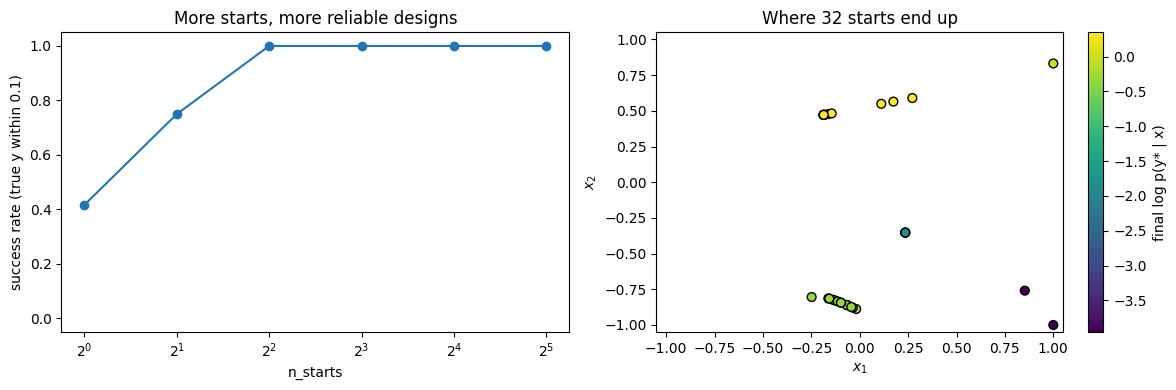

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.semilogx(starts, success, "o-", base=2)
ax.set(xlabel="n_starts", ylabel="success rate (true y within 0.1)", ylim=(-0.05, 1.05),
       title="More starts, more reliable designs")
ax = axes[1]
sc = ax.scatter(x_all[:, 0], x_all[:, 1], c=lls, cmap="viridis", s=40, edgecolor="k")
plt.colorbar(sc, ax=ax, label="final log p(y* | x)")
ax.set(xlabel="$x_1$", ylabel="$x_2$", xlim=(-1.05, 1.05), ylim=(-1.05, 1.05),
       title="Where 32 starts end up")
plt.tight_layout()
plt.show()
summary["inverse"] = (starts, success, x_all, lls)

## 3. No epistemic uncertainty away from the data

Train on $x \in [-2, 2]$ only and predict on $[-5, 5]$. A model with parameter uncertainty (a GP, a Bayesian model, or an ensemble) would widen its intervals outside the training range. A single difftree cannot: outside the data every input routes to an edge leaf, which predicts that leaf's mean and noise. We compare the single model's $\pm 2\sigma$ band with the spread of the means of 8 trees trained from different seeds, a cheap ensemble.

In [6]:
r3 = np.random.default_rng(3)
xt = r3.uniform(-2, 2, (300, 1))
f3 = lambda x: np.sin(1.5 * x) + 0.3 * x
yt = f3(xt[:, 0]) + 0.1 * r3.normal(size=300)
xe = np.linspace(-5, 5, 800)[:, None]

ens = [DifferentiableTreeRegressor(depth=4, n_epochs=150, random_state=s).fit(xt, yt) for s in range(8)]
mean0, std0 = ens[0].predict(xe, return_std=True)
means = np.stack([e.predict(xe) for e in ens])
inside = np.abs(xe[:, 0]) <= 2
err = np.abs(mean0 - f3(xe[:, 0]))
print(f"single model: mean sigma inside {std0[inside].mean():.3f}, outside {std0[~inside].mean():.3f}")
print(f"              mean |error| inside {err[inside].mean():.3f}, outside {err[~inside].mean():.3f}")
print(f"ensemble:     std of means inside {means.std(0)[inside].mean():.3f}, outside {means.std(0)[~inside].mean():.3f}")
cover = np.mean(np.abs(mean0 - f3(xe[:, 0]))[~inside] <= 2 * std0[~inside])
print(f"fraction of the true curve inside the single model's 2-sigma band, outside the data: {cover:.2f}")

single model: mean sigma inside 0.202, outside 0.198
              mean |error| inside 0.123, outside 0.792
ensemble:     std of means inside 0.060, outside 0.108
fraction of the true curve inside the single model's 2-sigma band, outside the data: 0.17


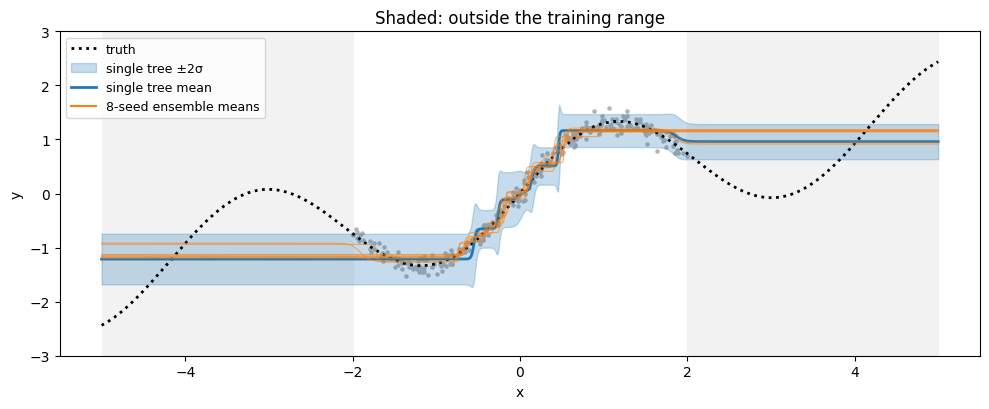

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axvspan(-5, -2, color="0.95"); ax.axvspan(2, 5, color="0.95")
ax.scatter(xt[:, 0], yt, s=5, color="0.7")
ax.plot(xe[:, 0], f3(xe[:, 0]), "k:", lw=2, label="truth")
ax.fill_between(xe[:, 0], mean0 - 2 * std0, mean0 + 2 * std0, color="C0", alpha=0.25, label="single tree ±2σ")
ax.plot(xe[:, 0], mean0, color="C0", lw=2, label="single tree mean")
for mu in means[1:]:
    ax.plot(xe[:, 0], mu, color="C1", lw=0.8, alpha=0.6)
ax.plot([], [], color="C1", label="8-seed ensemble means")
ax.set(xlabel="x", ylabel="y", ylim=(-3, 3), title="Shaded: outside the training range")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()
summary["extrap"] = (xt, yt, xe, f3, mean0, std0, means)

## 4. Oblique splits mix several inputs

Friedman #1 with 10 inputs, of which only $x_0 \dots x_4$ matter. Below are the absolute split weights $|w_i|$ of a depth-3 difftree (7 splits, standardized inputs), each row normalised to sum to one, next to the one input each scikit-learn split uses. A classic split reads as "$x_3 < 0.42$"; an oblique split is a weighted sum of inputs. The *effective number of inputs* per split is $1 / \sum_j \tilde w_j^2$ for the normalised weights $\tilde w$: 1 for an axis-aligned split, 10 for equal weights on all ten.

In [8]:
Xf, yf = make_friedman1(n_samples=3000, n_features=10, noise=0.5, random_state=0)
mf = DifferentiableTreeRegressor(depth=3, n_epochs=150, random_state=0).fit(Xf, yf)
Wabs = np.abs(mf.params_["W"])                         # standardized inputs: comparable scales
Wn = Wabs / Wabs.sum(1, keepdims=True)
eff = 1.0 / (Wn ** 2).sum(1)                           # effective number of inputs per split
sk3 = DecisionTreeRegressor(max_depth=3, random_state=0).fit(Xf, yf)
print("effective inputs per difftree split:", np.round(eff, 1))
print("share of |w| on the 5 noise inputs:  ", np.round(Wn[:, 5:].sum(1), 2))
print("sklearn split features:", [int(f) for f in sk3.tree_.feature if f >= 0])

effective inputs per difftree split: [4.3 5.  3.9 5.1 4.8 3.9 4.8]
share of |w| on the 5 noise inputs:   [0.1  0.04 0.05 0.06 0.03 0.05 0.06]
sklearn split features: [3, 1, 4, 0, 0, 4, 1]


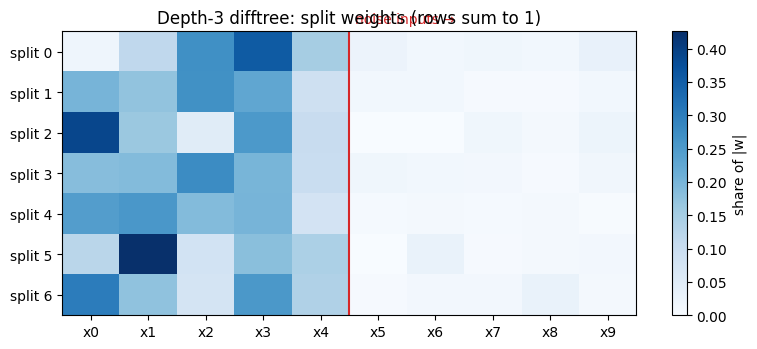

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(Wn, cmap="Blues", aspect="auto", vmin=0)
plt.colorbar(im, ax=ax, label="share of |w|")
ax.set_xticks(range(10), [f"x{j}" for j in range(10)])
ax.set_yticks(range(Wn.shape[0]), [f"split {i}" for i in range(Wn.shape[0])])
ax.axvline(4.5, color="C3", lw=1.5)
ax.text(4.6, -0.7, "noise inputs →", color="C3", fontsize=10)
ax.set_title("Depth-3 difftree: split weights (rows sum to 1)")
plt.tight_layout()
plt.show()
summary["weights"] = Wn

## Summary figure for the deck

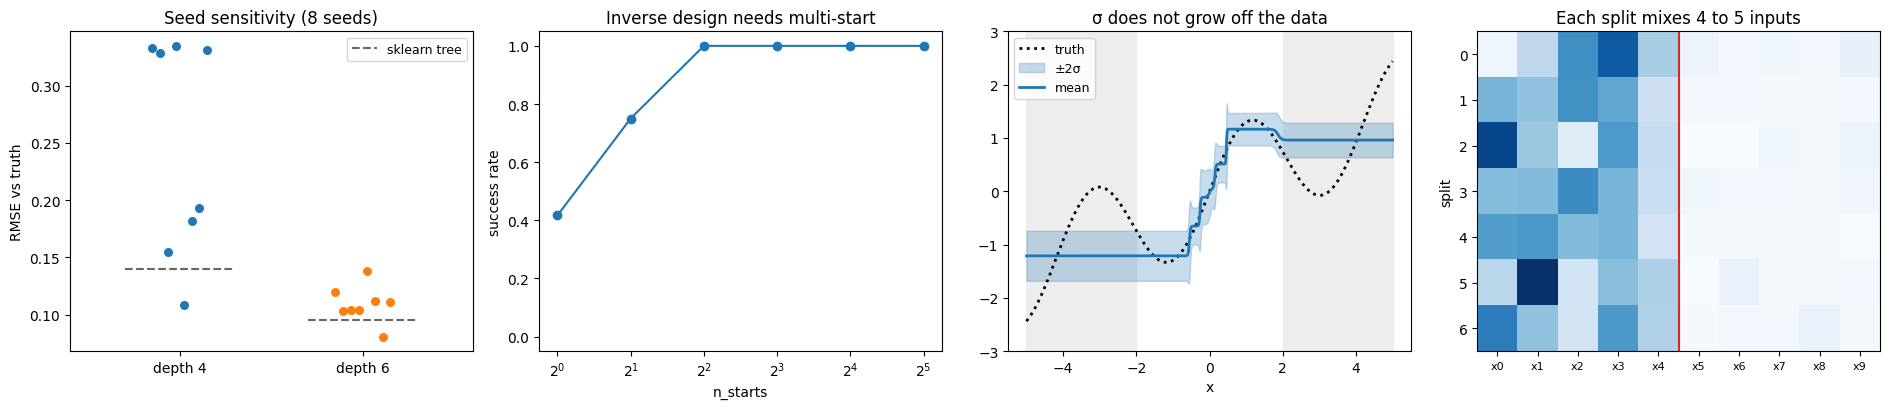

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
ax = axes[0]
for i, D in enumerate((4, 6)):
    r = summary["seeds"][D]
    ax.scatter(np.full(len(r), i) + np.linspace(-0.15, 0.15, len(r)), r, s=30, color=f"C{i}")
    ax.hlines(sk_rmse[D], i - 0.3, i + 0.3, color="0.4", ls="--", label="sklearn tree" if i == 0 else None)
ax.set_xticks([0, 1], ["depth 4", "depth 6"]); ax.set_xlim(-0.6, 1.6)
ax.legend(fontsize=9)
ax.set(ylabel="RMSE vs truth", title="Seed sensitivity (8 seeds)")

ax = axes[1]
st, succ, xa, ll = summary["inverse"]
ax.semilogx(st, succ, "o-", base=2)
ax.set(xlabel="n_starts", ylabel="success rate", ylim=(-0.05, 1.05), title="Inverse design needs multi-start")

ax = axes[2]
xt_, yt_, xe_, f_, m0, s0, ms = summary["extrap"]
ax.axvspan(-5, -2, color="0.93"); ax.axvspan(2, 5, color="0.93")
ax.plot(xe_[:, 0], f_(xe_[:, 0]), "k:", lw=2, label="truth")
ax.fill_between(xe_[:, 0], m0 - 2 * s0, m0 + 2 * s0, color="C0", alpha=0.25, label="±2σ")
ax.plot(xe_[:, 0], m0, color="C0", lw=2, label="mean")
ax.set(xlabel="x", ylim=(-3, 3), title="σ does not grow off the data")
ax.legend(fontsize=9, loc="upper left")

ax = axes[3]
im = ax.imshow(summary["weights"], cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(10), [f"x{j}" for j in range(10)], fontsize=8)
ax.axvline(4.5, color="C3", lw=1.5)
ax.set(ylabel="split", title="Each split mixes 4 to 5 inputs")
plt.tight_layout()
fig.savefig(FIG / "failure_modes.png", dpi=150)
plt.show()

## What this shows

**Seeds.** At depth 4 the eight seeds give RMSE from 0.11 to 0.34 against the truth, a factor of three, and half of them are worse than a greedy scikit-learn tree of the same depth (0.14). The bad seeds park leaves on flat plateaus and miss whole sections of the curve. Depth 6 is far more stable (0.08 to 0.14) because spare leaves make up for badly placed splits. Choosing the seed by $R^2$ on held-out data picked the best seed at both depths, so the practical fix is cheap: fit several seeds and keep the best on validation data.

**Inverse design.** One start succeeds only 42% of the time; four or more starts succeeded in all 12 repeats here. The 32-start run ends in six distinct optima spread over the box, with nearly equal likelihood, so the problem is genuinely multimodal and a single gradient ascent finds whichever basin it starts in. The remaining error of about 0.09 is the surrogate's own error, not the optimizer's. Use `n_starts` of 16 or more and look at `x_all`, which often holds useful alternative designs.

**Extrapolation.** The single tree's $\sigma$ is the same inside and outside the training range (about 0.20), while its error grows from 0.12 to 0.79. Outside the data the $2\sigma$ band covers only 17% of the true curve. The 8-seed ensemble's spread does grow outside (0.06 to 0.11), but far less than the error. Neither is a substitute for keeping queries inside the data, so check that inputs are in the training box before trusting an interval.

**Readability.** Each split mixes about 4 to 5 inputs, compared with exactly one for the scikit-learn tree. Training does learn to ignore the five noise inputs (3 to 10% of the weight), so the weights are informative, but a split is a hyperplane rather than a threshold. Shallow trees, or reading off the dominant weights of each split, are the practical compromise.